In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cus = pd.read_csv('olist_customers_dataset.csv',
                  dtype={'customer_zip_code_prefix': str})   # keeps leading zeros
print(cus.shape)
cus.head()

(99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [3]:
print(cus.dtypes, "\n")
print("Missing values per column:\n", cus.isna().sum(), "\n")
print("Distinct values per column:\n", cus.nunique())

customer_id                 object
customer_unique_id          object
customer_zip_code_prefix    object
customer_city               object
customer_state              object
dtype: object 

Missing values per column:
 customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64 

Distinct values per column:
 customer_id                 99441
customer_unique_id          96096
customer_zip_code_prefix    14994
customer_city                4119
customer_state                 27
dtype: int64


In [4]:
#Rule: zip is a 5-digit string
cus['customer_zip_code_prefix'] = cus['customer_zip_code_prefix'].str.strip().str.zfill(5)

valid_zip = cus['customer_zip_code_prefix'].str.fullmatch(r'\d{5}')
print("Invalid zip codes:", (~valid_zip).sum())
cus = cus[valid_zip]

Invalid zip codes: 0


In [5]:
#Rule: consistent text format
cus['customer_city']  = cus['customer_city'].str.strip().str.lower()
cus['customer_city']  = cus['customer_city'].str.replace(r'\s+', ' ', regex=True)   # remove double spaces
cus['customer_state'] = cus['customer_state'].str.strip().str.upper()
print("Done")

Done


In [8]:
#Rule: valid Brazilian state
UF = ['AC','AL','AP','AM','BA','CE','DF','ES','GO','MA','MT','MS','MG','PA',
      'PB','PR','PE','PI','RJ','RN','RS','RO','RR','SC','SP','SE','TO']


valid_state = cus['customer_state'].isin(UF)
print("Invalid states:", (~valid_state).sum())
cus = cus[valid_state]

Invalid states: 0


In [9]:
#Rule: valid IDs and no duplicates#
hex32 = r'[0-9a-f]{32}'
valid_id = (cus['customer_id'].str.fullmatch(hex32) &
            cus['customer_unique_id'].str.fullmatch(hex32))
print("Invalid IDs:", (~valid_id).sum())
cus = cus[valid_id]

print("Duplicate rows:       ", cus.duplicated().sum())
print("Duplicate customer_id:", cus['customer_id'].duplicated().sum())
cus = cus.drop_duplicates(subset='customer_id').reset_index(drop=True)

Invalid IDs: 0
Duplicate rows:        0
Duplicate customer_id: 0


In [10]:
#save
from google.colab import files
cus.to_csv('olist_customers_clean.csv', index=False)
files.download('olist_customers_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

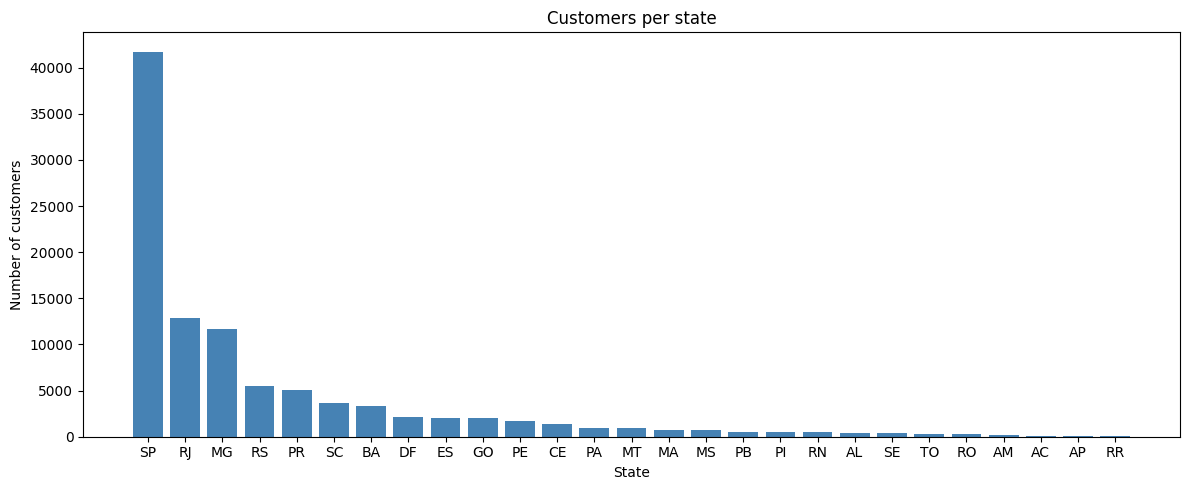

Share of customers (%):
customer_state
SP    42.0
RJ    12.9
MG    11.7
RS     5.5
PR     5.1
Name: count, dtype: float64


In [11]:
#Viz 1: Customers per state
state_counts = cus['customer_state'].value_counts()

plt.figure(figsize=(12, 5))
plt.bar(state_counts.index, state_counts.values, color='steelblue')
plt.title('Customers per state')
plt.xlabel('State')
plt.ylabel('Number of customers')
plt.tight_layout()
plt.show()

print("Share of customers (%):")
print((state_counts / state_counts.sum() * 100).round(1).head(5))

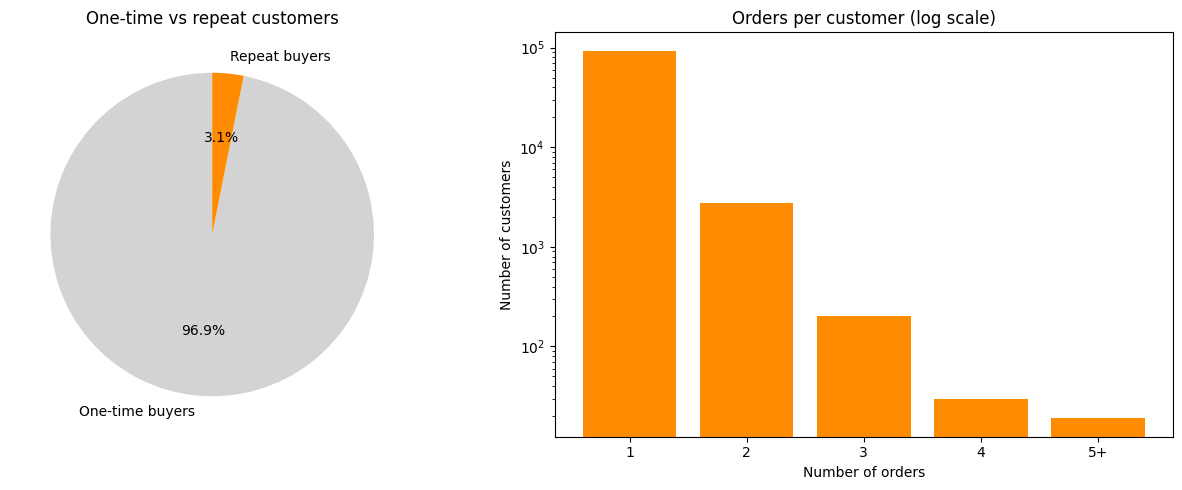

One-time: 93099 | Repeat: 2997


In [13]:
#Viz 3: One-time vs repeat customers
orders_per_person = cus['customer_unique_id'].value_counts()
one_time = (orders_per_person == 1).sum()
repeat   = (orders_per_person > 1).sum()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].pie([one_time, repeat], labels=['One-time buyers', 'Repeat buyers'],
          autopct='%1.1f%%', colors=['lightgray', 'darkorange'], startangle=90)
ax[0].set_title('One-time vs repeat customers')

dist = orders_per_person.clip(upper=5).value_counts().sort_index()
ax[1].bar(['1', '2', '3', '4', '5+'][:len(dist)], dist.values, color='darkorange')
ax[1].set_yscale('log')
ax[1].set_title('Orders per customer (log scale)')
ax[1].set_xlabel('Number of orders')
ax[1].set_ylabel('Number of customers')

plt.tight_layout()
plt.show()
print("One-time:", one_time, "| Repeat:", repeat)

Customers without coordinates: 279


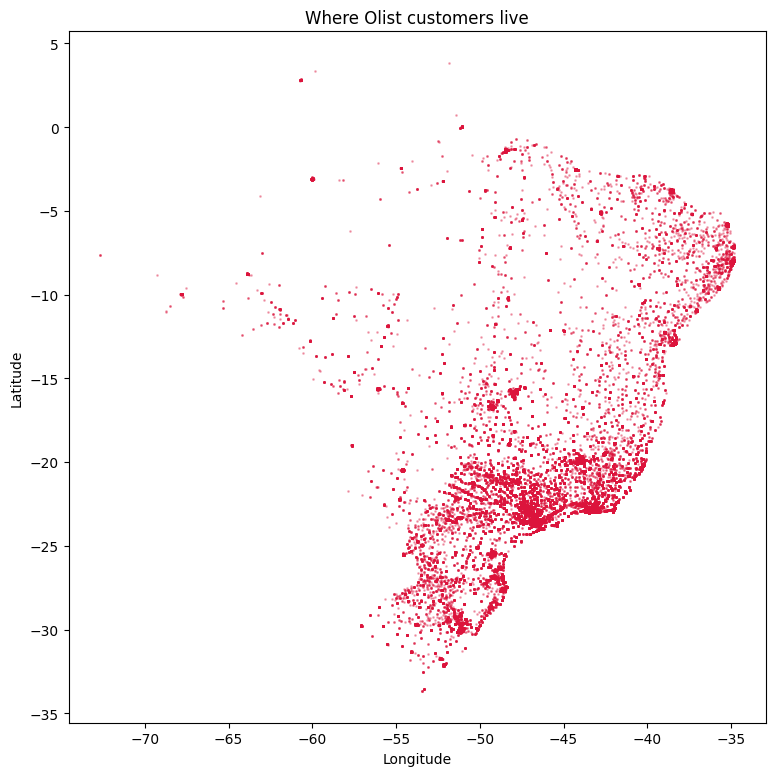

In [14]:
#Viz 3: Map of customers
geo = pd.read_csv('olist_geolocation_clean.csv',
                  dtype={'geolocation_zip_code_prefix': str})

zip_xy = (geo.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']]
             .mean()
             .rename(columns={'geolocation_lat': 'lat', 'geolocation_lng': 'lng'}))

cus_map = cus.join(zip_xy, on='customer_zip_code_prefix')
print("Customers without coordinates:", cus_map['lat'].isna().sum())

plt.figure(figsize=(9, 9))
plt.scatter(cus_map['lng'], cus_map['lat'], s=1, alpha=0.3, color='crimson')
plt.title('Where Olist customers live')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.gca().set_aspect('equal')
plt.show()

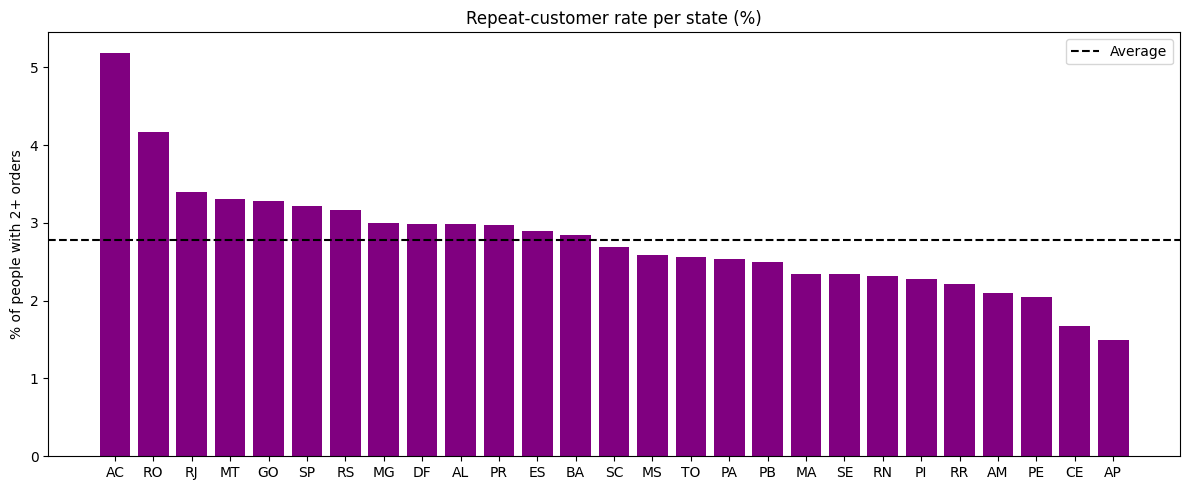

,customers,people,repeat_rate_%
customer_state,,,
AC,81,77,5.19
RO,253,240,4.17
RJ,12852,12384,3.40
MT,907,876,3.31
GO,2020,1952,3.28


In [15]:
#Viz 4: Repeat-customer rate per state
by_state = cus.groupby('customer_state').agg(customers=('customer_id', 'size'),
                                              people=('customer_unique_id', 'nunique'))
by_state['repeat_rate_%'] = (cus.groupby('customer_state')['customer_unique_id']
                             .apply(lambda s: (s.value_counts() > 1).mean()) * 100).round(2)
by_state = by_state.sort_values('repeat_rate_%', ascending=False)

plt.figure(figsize=(12, 5))
plt.bar(by_state.index, by_state['repeat_rate_%'], color='purple')
plt.axhline(by_state['repeat_rate_%'].mean(), color='black', linestyle='--', label='Average')
plt.title('Repeat-customer rate per state (%)')
plt.ylabel('% of people with 2+ orders')
plt.legend()
plt.tight_layout()
plt.show()

by_state.head()